Andrés Oto

Regresion Logistica

3. Utilizando los dataset provistos (Social_Network) entrene, un modelo de regresión logística, haga predicciones, realice una matriz de confusión, defina las métricas de evaluación y explique sus resultados.

In [2]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix, 
                             ConfusionMatrixDisplay, classification_report)

In [2]:
#Cargo el dataset
df=pd.read_csv("Social_Network_Ads.xls")

In [3]:
#Como solo hay dos variables convertimos a numerico 'Gender' 0 y 1
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})


In [4]:
#Se elige variables X y Y
#Se usará Gender, Age y EstimatedSalary en X y en Y "Purchased"
X = df[['Gender', 'Age', 'EstimatedSalary']]
y = df['Purchased']


In [5]:
#Test y entrenamiento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Investigando sobre regresión logística, se recomienda:
Escalar los datos porque variables como el Salario (miles) y la Edad (decenas) tienen 
escalas muy distintas. Esto evita que el Salario domine al modelo y acelera el algoritmo.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
#Escalar las características
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Entrenar el modelo
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [7]:
#Predicciones
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1] #ROC-AUC

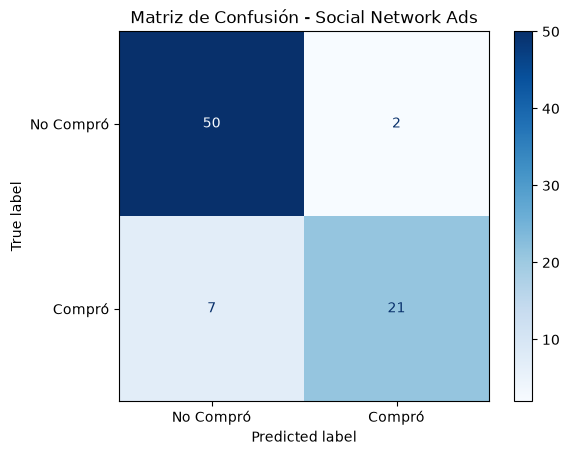

In [11]:
# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Compró", "Compró"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión - Social Network Ads")
plt.show()

In [8]:
# Métricas de Evaluación
print("--- Métricas---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")
print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred)) 

--- Métricas---
Accuracy:  0.8875
Precision: 0.9130
Recall:    0.7500
F1 Score:  0.8235
ROC-AUC:   0.9705

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.88      0.96      0.92        52
           1       0.91      0.75      0.82        28

    accuracy                           0.89        80
   macro avg       0.90      0.86      0.87        80
weighted avg       0.89      0.89      0.88        80



# DATASET IRIS FLOWERS


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, 
                             ConfusionMatrixDisplay, classification_report)

In [10]:
# Cargo el dataset
df = pd.read_csv("Iris_flower.csv")

# Limpio los nombres de las columnas por si tienen espacios
df.columns = df.columns.str.strip()

# Como hay 3 tipos de flores (texto), las convierto a números (0, 1, 2)
df['Species'] = df['Species'].astype(str).str.strip().replace({
    'I. setosa': 0,
    'I. versicolor': 1,
    'I. virginica': 2
})

print("Valores nulos en Species:", df['Species'].isna().sum())

Valores nulos en Species: 0


In [11]:
# Se eligen variables X y Y
# Se usarán las 4 características de la flor en X y la 'Species' en Y
X_iris = df[['Sepal length', 'Sepal width', 'Petal length', 'Petal width']]
y_iris = df['Species']

In [12]:
# Test y entrenamiento para Iris
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(X_iris, y_iris, test_size=0.2, random_state=42)

# Escalar datos
scaler_iris = StandardScaler()
X_train_scaled_iris = scaler_iris.fit_transform(X_train_iris)
X_test_scaled_iris = scaler_iris.transform(X_test_iris)

# Entrenar modelo
model_iris = LogisticRegression(random_state=42)
model_iris.fit(X_train_scaled_iris, y_train_iris)

# Predicciones
y_pred_iris = model_iris.predict(X_test_scaled_iris)



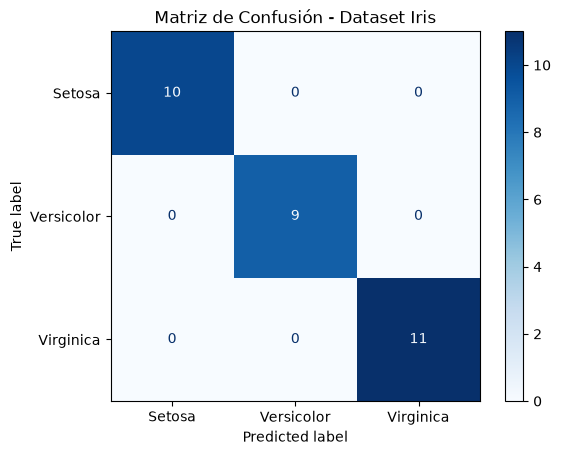

In [24]:
# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                              display_labels=["Setosa", "Versicolor", "Virginica"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión - Dataset Iris")
plt.show()

In [14]:
# Métricas 
print("--- Métricas---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")

#  se usa 'average' para promediar las 3 clases
print(f"Precision: {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\n\t\t--- Reporte ---")
print(classification_report(y_test_iris, y_pred_iris, target_names=["Setosa", "Versicolor", "Virginica"]))

--- Métricas---
Accuracy:  0.8875
Precision: 0.8951
Recall:    0.8558
F1 Score:  0.8705

		--- Reporte ---
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00         9
   Virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

